In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import json
import os
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:

BASE_DIR = Path.cwd()
DATASET_DIR = BASE_DIR / "Dataset" / "LumbarSpinalStenosis" / "LumbarSpinalStenosis"
MODEL_DIR = BASE_DIR / "saved_models"

model_path = MODEL_DIR / "efficientnet.pth"

test_df = pd.read_csv(BASE_DIR / "test_split.csv")

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
with open("label_map.json") as f:
    label_map = json.load(f)

idx_to_label = {v: k for k, v in label_map.items()}
class_names = list(label_map.keys())

In [5]:
inference_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

In [6]:
class MRIDataset(Dataset):
    def __init__(self, df, transform=None, root_dir=DATASET_DIR):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.root_dir = Path(root_dir)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.root_dir / row["image_path"]
        image = Image.open(img_path).convert("L")
        label = label_map[row["label"]]
        if self.transform:
            image = self.transform(image)
        return image, label

In [7]:
test_df = pd.read_csv("test_split.csv")

test_dataset = MRIDataset(test_df, transform=inference_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test samples:", len(test_dataset))

Test samples: 2607


In [8]:
from torchvision import models
import torch.nn as nn
import torch

def build_efficientnet_b0(num_classes=3):
    effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

    # Get original first conv layer
    first_conv = effnet.features[0][0]

    # New conv for 1-channel input, same settings as first_conv
    new_conv = nn.Conv2d(
        in_channels=1,
        out_channels=first_conv.out_channels,
        kernel_size=first_conv.kernel_size,
        stride=first_conv.stride,
        padding=first_conv.padding,
        bias=False
    )

    # Initialize weights by averaging over RGB channels
    with torch.no_grad():
        new_conv.weight = nn.Parameter(first_conv.weight.mean(dim=1, keepdim=True))

    # Replace in the model
    effnet.features[0][0] = new_conv

    # Replace classifier head for 3 classes
    in_features = effnet.classifier[1].in_features
    effnet.classifier[1] = nn.Linear(in_features, num_classes)

    return effnet

In [9]:
def evaluate_model(model, loader):
    model.eval()

    all_labels, all_preds = [], []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)

    acc = (all_labels == all_preds).mean() * 100
    bal_acc = balanced_accuracy_score(all_labels, all_preds) * 100

    print(f"Test Accuracy: {acc:.2f}%")
    print(f"Balanced Accuracy: {bal_acc:.2f}%\n")

    print("Classification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix (Test)")
    plt.show()

In [10]:
model = build_efficientnet_b0(num_classes=3)
model.load_state_dict(torch.load(MODEL_DIR / "efficientnet.pth", map_location=device))
model = model.to(device)
model.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

Test Accuracy: 89.07%
Balanced Accuracy: 89.34%

Classification Report:

                precision    recall  f1-score   support

Herniated Disc      0.814     0.951     0.877       800
   No Stenosis      0.925     0.877     0.900       860
    Thecal Sac      0.942     0.852     0.895       947

      accuracy                          0.891      2607
     macro avg      0.894     0.893     0.891      2607
  weighted avg      0.897     0.891     0.891      2607



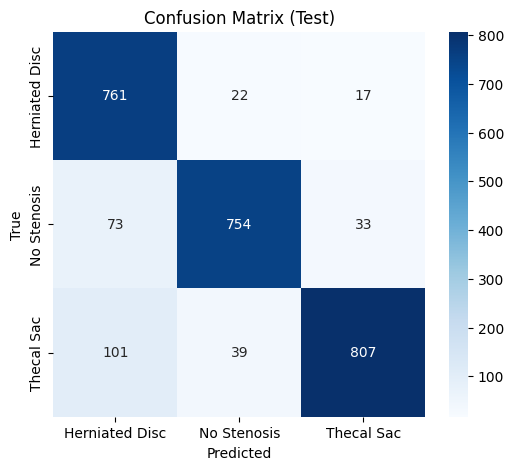

In [11]:
evaluate_model(model, test_loader)

In [12]:
def predict_image(image_path):
    image = Image.open(image_path).convert("L")
    image = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image)
        probs = torch.softmax(outputs, dim=1)
        pred_idx = torch.argmax(probs, dim=1).item()

    print("Prediction:", idx_to_label[pred_idx])
    print("Probabilities:", probs.cpu().numpy().flatten())